## Problem 9
Write a Python program to perform contrast stretching and bit-plane slicing.

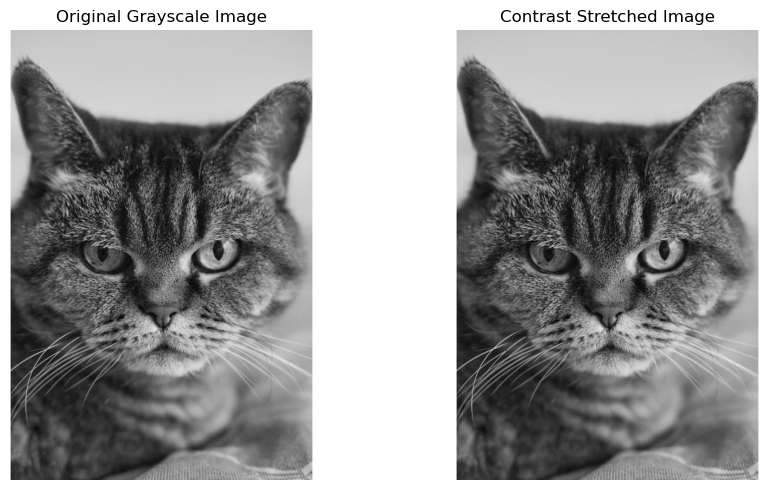

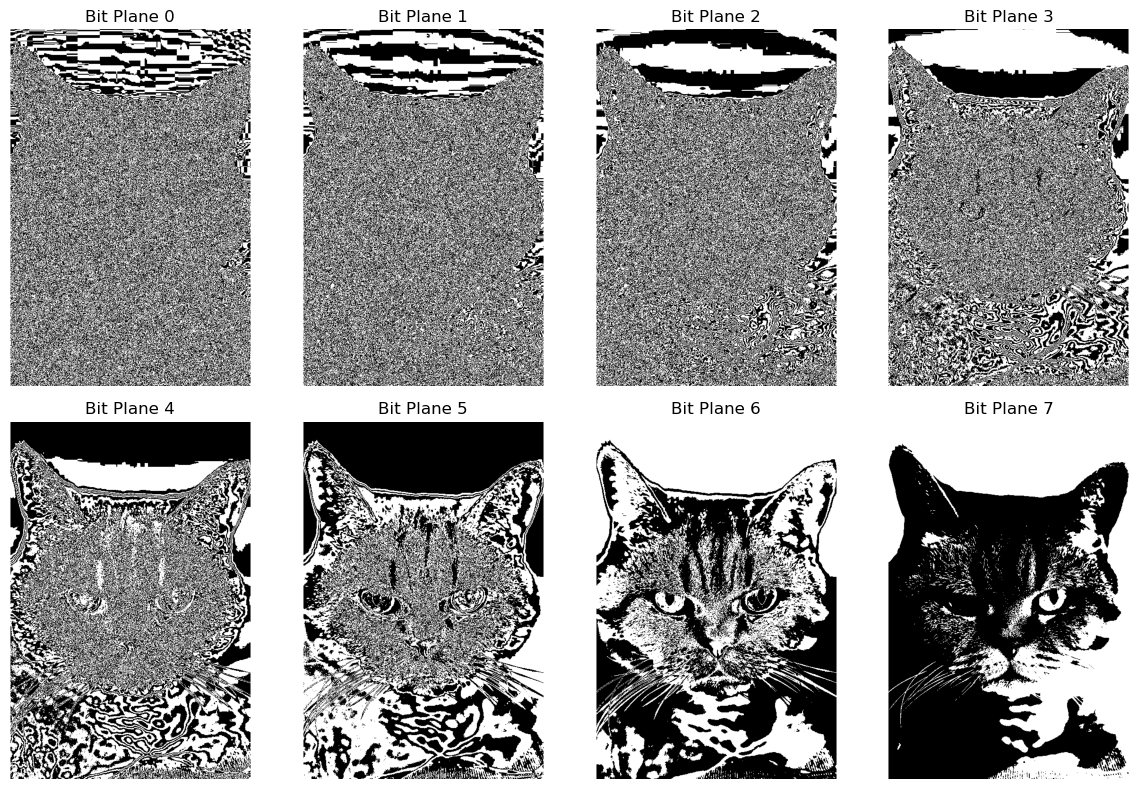

In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

image = cv2.imread("cat.png")
height, width = image.shape[:2]
gray = np.zeros((height, width), dtype=np.uint8)
stretched = np.zeros((height, width), dtype=np.uint8)
bit_planes = []

# Convert the color image to grayscale manually.
for row in range(height):
    for col in range(width):
        blue = int(image[row, col, 0])
        green = int(image[row, col, 1])
        red = int(image[row, col, 2])
        gray[row, col] = int(0.114 * blue + 0.587 * green + 0.299 * red)

# Find minimum and maximum values manually.
minimum = gray[0, 0]
maximum = gray[0, 0]
for row in range(height):
    for col in range(width):
        if gray[row, col] < minimum:
            minimum = gray[row, col]
        if gray[row, col] > maximum:
            maximum = gray[row, col]

# Contrast stretching manually.
for row in range(height):
    for col in range(width):
        if maximum == minimum:
            stretched[row, col] = gray[row, col]
        else:
            stretched[row, col] = int(
                (int(gray[row, col]) - int(minimum)) * 255 / (int(maximum) - int(minimum))
            )

# Create all 8 bit planes manually.
for bit in range(8):
    plane = np.zeros((height, width), dtype=np.uint8)
    bit_value = 2 ** bit
    for row in range(height):
        for col in range(width):
            if gray[row, col] & bit_value:
                plane[row, col] = 255
    bit_planes.append(plane)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(stretched, cmap="gray")
plt.title("Contrast Stretched Image")
plt.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))
for bit in range(8):
    plt.subplot(2, 4, bit + 1)
    plt.imshow(bit_planes[bit], cmap="gray")
    plt.title("Bit Plane " + str(bit))
    plt.axis("off")
plt.tight_layout()
plt.show()
